In [ ]:
import re
import os
from tqdm import tqdm
from collections import defaultdict, Counter

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pydub import AudioSegment
import opensmile

from transformers import AutoTokenizer, AutoModel
from transformers import BertForMaskedLM, BertTokenizer, Trainer, TrainingArguments, DataCollatorForLanguageModeling
from transformers import BertModel
from sklearn.model_selection import train_test_split, cross_val_score
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau, LinearLR
from torch.utils.data import Dataset, DataLoader, Subset
from datasets import Dataset as ds
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import compute_class_weight
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

import shap
from enum import Enum
import umap.umap_ as umap
from imblearn.over_sampling import SMOTE

# set type of tokenizer
model_types = ['bert-base-uncased', 'bert-large-uncased', 'ClinicalBERT', 
               'deberta-v3-base', 'roberta-base', 'roberta-large',
               'bge-base-en-v1.5', 'bge-m3'] # m3 is multi-lingual
MODEL_TYPE = model_types[6]
MAX_POOLING = False
FINE_TUNE = False

# Load data

In [76]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [77]:
if MAX_POOLING:
    df = pd.read_pickle(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_MAXP_{MODEL_TYPE}.pkl')
else:
    df = pd.read_pickle(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_{MODEL_TYPE}.pkl')

In [78]:
df['dementia'].unique()

array(['PossibleAD', 'ProbableAD', 'Memory', 'Vascular', 'MCI', 'Other',
       'Probable', 'Control'], dtype=object)

In [79]:
df

,ID,age,sex,dementia,text,embeddings,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
0,476-0_cookie,64,female,PossibleAD,clearsthroat hm the woman of the house is dryi...,"[[0.3502416, 0.2750996, -0.99398524, -0.138231...",32.367973,0.169069,28.859549,32.672092,...,0.014956,-0.010772,0.069282,4.552497,3.578753,0.414964,0.119592,0.077508,0.064468,-29.202118
1,183-1_cookie,64,male,ProbableAD,the boy's uh fallin off the stool the the girl...,"[[-0.1042838, 0.84787285, -0.5198379, 0.005333...",25.893515,0.083554,25.068998,26.007025,...,0.019386,-0.003246,0.022419,2.437523,1.581530,0.449667,0.280772,0.284074,0.188013,-31.610138
2,216-0_cookie,72,female,ProbableAD,well there's a kid in a cookie jar there's a g...,"[[-0.3063795, 0.579951, -0.56298494, 0.0945558...",30.133780,0.158424,26.081902,31.247602,...,0.036977,-0.013100,0.038447,3.465397,2.478610,0.336407,0.197328,0.126481,0.055212,-37.809464
3,173-1_cookie,71,female,ProbableAD,let's see what's this this well the k lu and t...,"[[0.70182806, 1.3164313, -1.0037489, -0.307378...",29.214741,0.193511,25.452457,28.852304,...,0.038325,-0.020275,0.022480,3.307396,2.552122,0.367143,0.228349,0.163214,0.070129,-46.272060
4,381-0_cookie,75,female,ProbableAD,well the kids are swipin the cookies mom's doi...,"[[-0.3898154, 0.7111167, -0.9341499, -0.539266...",27.629732,0.074770,26.195204,28.142347,...,0.037889,-0.009598,0.008773,3.657219,2.840905,0.122197,0.068713,0.360424,0.285403,-53.288258
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1208,128-1_cookie,71,female,Control,oh I remember this one okay the mom's doing th...,"[[-0.26460212, 0.38948008, -0.96125656, -0.143...",30.967085,0.103636,28.283186,30.838778,...,0.054463,-0.014791,0.021959,3.372949,2.116813,0.310652,0.159613,0.214994,0.122742,-45.492466
1209,142-3_cookie,61,female,Control,mhm well the water's running over on the floor...,"[[-0.4683905, 0.85836834, -0.5786724, -0.09417...",33.519424,0.088880,32.100095,33.175519,...,0.056380,-0.012752,0.024856,4.028542,1.806884,0.417500,0.195181,0.095458,0.067621,-29.882867
1210,332-0_fluency,50,male,Control,dog cow cat horse sheep mule donkey deer antel...,"[[0.027599737, -0.40143248, -0.8672837, 0.2189...",26.910131,0.028706,26.678370,27.039707,...,-0.001642,-0.000825,0.011415,1.168898,0.703156,0.265128,0.025641,1.202970,0.899072,-54.753613
1211,332-0_recall,50,male,Control,eorge and his granddaughter went to visit ( ) ...,"[[0.13735177, 0.3312348, -0.4347563, -0.518712...",25.061729,0.053765,24.179365,24.968309,...,0.002817,-0.002691,0.013942,3.129667,1.758500,0.162454,0.099134,0.416941,0.612056,-54.896027


In [80]:
df['embeddings'][0].shape

(1, 1024)

In [81]:
def encode_df(df):
    SIMPLE = True

    sex_mapping = {'female': 0,
                   'male': 1}
    dementia_mapping = {'Control' : 0,
                        'PossibleAD' : 1,
                        'ProbableAD' : 1,
                        'Probable' : 1,
                        'Memory' : 2,
                        'Vascular' : 3,
                        'MCI' : 4,
                        'Other' : 5}

    simple_dementia_mapping = {'Control' : 0,
                        'PossibleAD' : 1,
                        'ProbableAD' : 1,
                        'Probable' : 1,
                        'Memory' : 1,
                        'Vascular' : 1,
                        'MCI' : 1,
                        'Other' : 1}
    df['sex'] = df['sex'].map(sex_mapping)

    # I suppose we can keep simple mapping, cuz 'PossibleAD' and 'ProbableAD' are the most common (like 80% of the data)
    if SIMPLE:
        df['dementia'] = df['dementia'].map(simple_dementia_mapping)
    else:
        df['dementia'] = df['dementia'].map(dementia_mapping)
    return df
df = encode_df(df)

In [82]:
print(f"cookie stats\n{df[df['ID'].str.contains(r'cookie$', regex=True)].groupby('dementia').size()}\n")
print(f"recall stats\n{df[df['ID'].str.contains(r'recall$', regex=True)].groupby('dementia').size()}\n")
print(f"fluency stats\n{df[df['ID'].str.contains(r'fluency$', regex=True)].groupby('dementia').size()}\n")
print(f"sentence stats\n{df[df['ID'].str.contains(r'sentence$', regex=True)].groupby('dementia').size()}\n")

cookie stats
dementia
0    243
1    306
dtype: int64

recall stats
dementia
0      1
1    238
dtype: int64

fluency stats
dementia
0      1
1    210
dtype: int64

sentence stats
dementia
0      1
1    213
dtype: int64



In [83]:
'''
BIG FUCKING PROBLEM. The non cookie data has only one control, which is bad in and of itself, so I will only use cookie data.
HOWEVER! Almost each patient has like from 2 to 5 samples (e.g. 123_0, 123_1 and so on), so when we split the data recordings 
of the same patient might appear in test and train at the same time. Fucking hell. Now I just merge their data.
'''
df = df[df['ID'].str.contains(r'cookie$', regex=True)]
df['ID'] = df['ID'].str.extract(r'^(\d{3})')
df = df.drop(columns=['text'])
df = df.groupby('ID', as_index=False).mean()
df = df[df['dementia'].isin([0, 1])] 


/tmp/ipykernel_121767/89803766.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ID'] = df['ID'].str.extract(r'^(\d{3})')


In [84]:
df

,ID,age,sex,dementia,embeddings,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
0,001,58.0,1.0,1.0,"[[-0.615955114364624, 0.46665796637535095, -0....",24.007486,0.249831,20.184769,22.278211,26.457061,...,0.029529,-0.009069,0.101949,3.104930,2.371126,0.477314,0.311443,0.106744,0.102437,-32.413410
1,002,59.5,0.0,0.0,"[[-0.2343405932188034, 0.4026533365249634, -1....",28.993107,0.122108,26.548655,28.391636,31.503487,...,0.044682,-0.003132,0.019453,2.879837,1.675057,0.245219,0.146539,0.571197,0.244049,-50.502188
2,003,56.0,1.0,1.0,"[[-0.750382661819458, 0.24339888989925385, -0....",23.200605,0.201415,20.125063,22.841703,25.770544,...,0.042396,-0.015316,0.182064,3.170367,1.757709,0.770903,0.539168,0.088298,0.105145,-29.459497
3,005,54.0,1.0,1.0,"[[-0.14835093915462494, 1.0408120155334473, -0...",23.708063,0.113381,20.987274,22.767417,26.742311,...,0.043387,-0.007752,0.040804,3.725629,1.614170,0.659851,0.114319,0.154628,0.032852,-39.530314
4,006,73.0,1.0,0.0,"[[-0.2841713825861613, 0.2698450485865275, -1....",26.026248,0.208428,23.685170,25.224073,27.665803,...,0.047626,-0.007929,0.091308,3.464252,1.937064,0.488675,0.295809,0.154428,0.145268,-29.243555
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286,705,71.0,0.0,1.0,"[[-0.6272964477539062, 0.3600788116455078, -0....",28.509546,0.235985,23.385406,29.888838,32.735504,...,0.021433,-0.003191,0.225758,3.565626,2.612877,0.321065,0.199789,0.083958,0.072360,-18.652487
287,707,74.0,0.0,1.0,"[[-0.663033127784729, 0.6922556757926941, -0.3...",28.969143,0.161608,26.807579,28.887688,31.861370,...,0.032612,-0.004763,0.202274,4.374685,2.322151,0.576619,0.253957,0.048577,0.020491,-21.267094
288,709,75.0,0.0,0.0,"[[-0.2938390374183655, 0.7032753825187683, -0....",29.200554,0.141155,26.425854,29.351512,32.293810,...,0.051244,-0.007034,0.123923,3.133558,2.192243,0.219631,0.140634,0.333764,0.217503,-40.202064
289,711,77.0,1.0,1.0,"[[-0.2488582283258438, 0.3103392422199249, -1....",24.532228,0.231943,21.884371,23.732145,25.483189,...,0.019180,-0.005968,0.461831,3.589783,2.220657,0.450595,0.346124,0.056059,0.043653,-18.531303


In [85]:
df.groupby('dementia').size()

dementia
0.0     98
1.0    192
dtype: int64

# Data prep

In [86]:
class PittDataset(Dataset):
    def __init__(self, embeddings, audio_features, age, sex, labels, audio_scaler=None, age_scaler=None, scale_audio=True):
        self.embeddings = embeddings
        self.audio_features = audio_features
        self.age = age.reshape(-1, 1)  # .reshape(-1,1) to keep it as a single feature
        self.sex = sex.reshape(-1, 1)
        self.labels = labels
        
        # Separate scalers for different features
        self.age_scaler = age_scaler or StandardScaler()

        if scale_audio:
            self.audio_scaler = audio_scaler or StandardScaler()
            
            if audio_scaler is None:
                self.audio_features = self.audio_scaler.fit_transform(self.audio_features)
            else:
                self.audio_features = self.audio_scaler.transform(self.audio_features)
            
        if age_scaler is None:
            self.age = self.age_scaler.fit_transform(self.age)
        else:
            self.age = self.age_scaler.transform(self.age)


    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'embeddings': torch.tensor(self.embeddings[idx], dtype=torch.float32),
            'audio_features': torch.tensor(self.audio_features[idx], dtype=torch.float32),
            'age': torch.tensor(self.age[idx], dtype=torch.float32),
            'sex': torch.tensor(self.sex[idx], dtype=torch.float32),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)  # Changed to long for CE loss
        }

In [87]:
def make_datasets(df): 
    embeddings = np.stack(df['embeddings'].values)
    if 'text' in df.columns:
        audio_features = df.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex', 'text']).values
        text = df['text'].values
    else:
        audio_features = df.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).values
    age = df['age'].values
    sex = df['sex'].values
    labels = df['dementia'].values

    '''
     there's some fuckery with embeddings, df['embeddings'].values returns an array with arrays inside with the shape of (n_samples,)
     it's like a list with these arrays, but we need to glue them together to get their real shape, that's why we use np.stack()
     however, it returns the needed array with the shape of (n_samples, 1, 768), and that's why we squeeze it
     as a result we get the shape of (n_samples, 768)
    '''
    if len(embeddings.shape) > 2:
        embeddings = np.squeeze(embeddings, axis=1)

    X_emb_train, X_emb_test, X_audio_train, X_audio_test, X_age_train, X_age_test, X_sex_train, X_sex_test, y_train, y_test = train_test_split(
        embeddings, 
        audio_features, 
        age, 
        sex,
        labels, test_size=0.2, stratify=df['dementia'])

    train_dataset = PittDataset(X_emb_train, X_audio_train, X_age_train, X_sex_train, y_train)
    test_dataset = PittDataset(X_emb_test, X_audio_test, X_age_test, X_sex_test, y_test, train_dataset.audio_scaler, train_dataset.age_scaler)
    print(f'Test: {Counter(y_test)}')
    print(f'Train: {Counter(y_train)}')
    
    return train_dataset, test_dataset, y_train, embeddings, audio_features, age, sex, labels


### Fine tune BERT on the other tasks

In [ ]:
if FINE_TUNE:
    bert_model = BertForMaskedLM.from_pretrained('bert-base-uncased')
    tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
    
    tuning_df = pd.read_pickle('/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_bert-base-uncased.pkl')
    tuning_df = tuning_df[~tuning_df['ID'].str.contains(r'cookie$', regex=True)]
    tuning_df = tuning_df[~tuning_df['dementia'].isin(['Control'])]  # fix: assign back to df
    
    list_of_dementia_texts = tuning_df['text'].tolist()
    
    dataset = ds.from_dict({"text": list_of_dementia_texts})
    
    def tokenize_function(examples):
        return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=512)
    
    tokenized_dataset = dataset.map(tokenize_function, batched=True, remove_columns=["text"])
    
    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=True, mlm_probability=0.15)
    
    training_args = TrainingArguments(
        output_dir='/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased-mlm',
        per_device_train_batch_size=8,
        num_train_epochs=3,
        save_steps=10_000,
        save_total_limit=2,
        prediction_loss_only=True,
        logging_steps=500,
    )
    
    trainer = Trainer(
        model=bert_model,
        args=training_args,
        train_dataset=tokenized_dataset,
        data_collator=data_collator,
    )
    
    trainer.train()

    bert_model.save_pretrained(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased_finetuned')
    tokenizer.save_pretrained(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased_finetuned')

    df = pd.read_pickle(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_bert-base-uncased.pkl')
    df['embeddings'] = np.nan
    fine_tuned_bert = BertModel.from_pretrained(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased_finetuned').to(device)
    def get_bert_embeddings(texts, model):
        inputs = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=512).to(device)
        with torch.no_grad():
            outputs = model(**inputs.to(device))
        return outputs.last_hidden_state.mean(dim=1).cpu().numpy() 
    
    tqdm.pandas(desc="Generating embeddings")
    df['embeddings'] = df['text'].progress_apply(get_bert_embeddings, model = fine_tuned_bert)
    df = encode_df(df)
    df = df[df['ID'].str.contains(r'cookie$', regex=True)]
    df['ID'] = df['ID'].str.extract(r'^(\d{3})')
    df = df.drop(columns=['text'])
    df = df.groupby('ID', as_index=False).mean()
    df = df[df['dementia'].isin([0, 1])] 

### Get datasets

In [89]:
train_dataset, test_dataset, y_train, embeddings, audio_features, age, sex, labels = make_datasets(df)
print("Scaled audio features stats:")
print(f"Min: {train_dataset.audio_features.min()}, Max: {train_dataset.audio_features.max()}")
print(f"Mean: {train_dataset.audio_features.mean()}, Std: {train_dataset.audio_features.std()}")
train_dataset.audio_features.shape

Test: Counter({np.float64(1.0): 38, np.float64(0.0): 20})
Train: Counter({np.float64(1.0): 154, np.float64(0.0): 78})
Scaled audio features stats:
Min: -14.54606515915954, Max: 14.037109954859453
Mean: -1.4617356437071026e-16, Std: 0.9999999999999999


(232, 88)

# Train Model


In [90]:
class PittNet(nn.Module):
    def __init__(self, emb_dim, audio_dim, num_classes, debug=False):
        super().__init__()

        self.embeddings_branch = nn.Sequential(
            nn.Linear(emb_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(128, 64)
        )

        self.audio_branch = nn.Sequential(
            nn.Linear(audio_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.4), 
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        self.demographics_branch = nn.Sequential(
            nn.Linear(2, 32),  # age + sex (label encoded)
            nn.GELU(),
            nn.Dropout(0.05),
            nn.Linear(32, 32),
            nn.GELU(),       
            nn.Linear(32, 64) 
        )

        self.classifier = nn.Sequential(
            nn.Linear(64+32+64, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

        self.debug = debug
        self.emb_mag = []
        self.audio_mag = []
        self.demo_mag = []
        self.temperature = nn.Parameter(torch.ones(1))
    
    
    def forward(self, embeddings, audio_features, age, sex):
        demo = torch.cat([age, sex], dim=1)
        emb_out = self.embeddings_branch(embeddings)
        audio_out = self.audio_branch(audio_features)
        demo_out = self.demographics_branch(demo)

        combined = torch.cat([emb_out, audio_out, demo_out], dim=1)

        if self.debug and torch.is_grad_enabled():  # Only log during training
            self.emb_mag.append((emb_out.norm(2, dim=1).mean().cpu().detach().numpy(), emb_out.norm(2, dim=1).std().cpu().detach().numpy())) # (mean mag per branch, std)
            self.audio_mag.append((audio_out.norm(2, dim=1).mean().cpu().detach().numpy(), audio_out.norm(2, dim=1).std().cpu().detach().numpy())) # (mean mag per branch, std)
            self.demo_mag.append((demo_out.norm(2, dim=1).mean().cpu().detach().numpy(), demo_out.norm(2, dim=1).std().cpu().detach().numpy())) # (mean mag per branch, std)

        return self.classifier(combined) / self.temperature, {'emb': self.emb_mag, 'audio': self.audio_mag , 'demo': self.demo_mag}



In [ ]:
def run_epochs(epochs, model, train_loader, test_loader, optimizer, loss_fn, patience=5, debug=False, plots=True):
    train_loss_his, train_acc_his = [], []
    test_loss_his, test_acc_his = [], []

    patience = patience
    best_loss = float('inf')
    best_auc = 0
    no_improve = 0


    for epoch in range(epochs):

        model.train()
        train_loss, train_acc = 0, 0

        all_preds = []
        all_labels = []

        for batch in train_loader:
            emb = batch['embeddings'].to(device)
            audio = batch['audio_features'].to(device)
            age = batch['age'].to(device)
            sex = batch['sex'].to(device)

            labels = batch['label'].to(device)

            logits, debug_data = model(emb, audio, age, sex)
            pred = F.softmax(logits, dim=1)

            loss = loss_fn(logits, labels)
            train_loss += loss.item()
            train_acc += accuracy_score(labels.cpu(), pred.argmax(dim=1).cpu())

            

            all_preds.extend(pred.argmax(dim=1).cpu())
            all_labels.extend(labels.cpu())

            optimizer.zero_grad()

            loss.backward()

            #torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

        train_loss /= len(train_loader)
        train_acc /= len(train_loader)
        train_loss_his.append(train_loss)
        train_acc_his.append(train_acc)
        train_f1 = f1_score(all_labels, all_preds)
        train_auc = roc_auc_score(all_labels, all_preds)
        train_recall = recall_score(all_labels, all_preds)
        train_precision = precision_score(all_labels, all_preds)
        train_con_mat = confusion_matrix(all_labels, all_preds)
        #train_report = classification_report(all_labels, all_preds)


        with torch.inference_mode():
            model.eval()
            test_loss, test_acc = 0, 0

            all_test_preds = []
            all_test_labels = []

            for batch in test_loader:
                emb = batch['embeddings'].to(device)
                audio = batch['audio_features'].to(device)
                age = batch['age'].to(device)
                sex = batch['sex'].to(device)

                test_labels = batch['label'].to(device)

                test_logits, _ = model(emb, audio, age, sex)
                test_pred = F.softmax(test_logits, dim=1)

                loss = loss_fn(test_logits, test_labels)

                test_loss += loss.item()
                test_acc += accuracy_score(test_labels.cpu(), test_pred.argmax(dim=1).cpu())

                all_test_preds.extend(test_pred.argmax(dim=1).cpu())
                all_test_labels.extend(test_labels.cpu())

            test_loss /= len(test_loader)
            test_acc /= len(test_loader)
            test_loss_his.append(test_loss)
            test_acc_his.append(test_acc)
            test_f1 = f1_score(all_test_labels, all_test_preds)
            test_auc = roc_auc_score(all_test_labels, all_test_preds)
            test_recall = recall_score(all_test_labels, all_test_preds)
            test_precision = precision_score(all_test_labels, all_test_preds)
            test_con_mat = confusion_matrix(all_test_labels, all_test_preds)
            #test_report = classification_report(all_test_labels, all_test_preds)

        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}:{epochs-1}------------------------") # 0 based counting, don't worry
            print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f} | Train F1: {train_f1:.2f} | Train AUC: {train_auc:.2f} | Train Recall: {train_recall:.2f} | Train Precision: {train_precision:.2f}")
            print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}  | Test F1: {test_f1:.2f} | Test AUC: {test_auc:.2f} | Test Recall: {test_recall:.2f} | Test Precision: {test_precision:.2f}")
            print(f"Confusion matrix cheatsheet: \n{np.array([['TN', 'FP'], ['FN', 'TP']])}")
            print(f"Train confusion matrix: \n{train_con_mat}")
            print(f"Test confusion matrix: \n{test_con_mat}\n")
            #print(f'Train: \n{train_report}')
            #print(f'Test: \n{test_report}\n')

        if test_loss < best_loss and test_auc > best_auc:
            best_loss = test_loss
            no_improve = 0
            final_metrics = {
                'train_acc': train_acc,
                'test_acc': test_acc,
                'train_f1': train_f1,
                'test_f1': test_f1,
                'train_auc': train_auc,
                'test_auc': test_auc,
                'train_recall': train_recall,
                'test_recall': test_recall,
                'train_precision': train_precision,
                'test_precision': test_precision,
                'test_confusion_matrix': test_con_mat,
            }
        else:
            no_improve += 1

        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch}")
            print(f"Epoch {epoch}:{epochs-1}------------------------") # 0 based counting, don't worry
            print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f} | Train F1: {train_f1:.2f} | Train AUC: {train_auc:.2f} | Train Recall: {train_recall:.2f} | Train Precision: {train_precision:.2f}")
            print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}  | Test F1: {test_f1:.2f} | Test AUC: {test_auc:.2f} | Test Recall: {test_recall:.2f} | Test Precision: {test_precision:.2f}")
            print(f"Confusion matrix cheatsheet: \n{np.array([['TN', 'FP'], ['FN', 'TP']])}")
            print(f"Train confusion matrix: \n{train_con_mat}")
            print(f"Test confusion matrix: \n{test_con_mat}\n")
            break
    
    if plots:
        fig, ax = plt.subplots()
        ax.plot(test_loss_his, label='Test loss')
        ax.plot(train_loss_his, label='Train loss')
        plt.ylim(0, 1) 
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
    
        fig, ax = plt.subplots()
        ax.plot(test_acc_his, label='Test accuracy')
        ax.plot(train_acc_his, label='Train accuracy')
        plt.ylim(0, 1) 
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend()

    test_report = classification_report(all_test_labels, all_test_preds)
    train_report = classification_report(all_labels, all_preds)
    
    print(f'Train: \n{train_report}')
    print(f'Test: \n{test_report}\n')

    

    if debug:
        emb_mag, emb_std = zip(*debug_data['emb'])
        audio_mag, audio_std = zip(*debug_data['audio'])
        demo_mag, demo_std = zip(*debug_data['demo'])

        branches = ["Embeddings", "Audio", "Demo"]
        l2_means = np.array([np.mean(emb_mag), np.mean(audio_mag), np.mean(demo_mag)])  # Mean L2 norms
        l2_stds = np.array([np.mean(emb_std), np.mean(audio_std), np.mean(demo_std)])    # Standard deviations
        plt.figure(figsize=(8, 5))
        plt.bar(branches, l2_means, yerr=l2_stds, capsize=5, color='skyblue', edgecolor='black')

        plt.title("L2 Norms of Branches (±Std Dev)", fontsize=14)
        plt.xlabel("Branch", fontsize=12)
        plt.ylabel("L2 Norm Magnitude", fontsize=12)
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        plt.show()
        print(f"\nBranch L2 Norms (Epoch Avg):")
        print(f"Emb: {np.mean(emb_mag):.2f} ± {np.mean(emb_std):.2f}")
        print(f"Audio: {np.mean(audio_mag):.2f} ± {np.mean(audio_std):.2f}") 
        print(f"Demo: {np.mean(demo_mag):.2f} ± {np.mean(demo_std):.2f}")

        return debug_data
    
    return final_metrics




In [92]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        BCE_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        F_loss = self.alpha * (1-pt)**self.gamma * BCE_loss
        
        if self.reduction == 'mean':
            return torch.mean(F_loss)
        elif self.reduction == 'sum':
            return torch.sum(F_loss)
        else:
            return F_loss
        
class HybridLoss(nn.Module):
    def __init__(self, alpha=0.5, gamma=1.5, ce_weight=0.3):
        super().__init__()
        self.focal = FocalLoss(alpha, gamma)
        self.ce = nn.CrossEntropyLoss()
        self.ce_weight = ce_weight
        
    def forward(self, inputs, targets):
        return (1-self.ce_weight)*self.focal(inputs, targets) + \
               self.ce_weight*self.ce(inputs, targets)

Tokenizer model: bge-m3 --- Average pooling
Epoch 0:999------------------------
Train loss: 0.38593 | Train accuracy: 0.58 | Train F1: 0.69 | Train AUC: 0.53 | Train Recall: 0.71 | Train Precision: 0.68
Test loss: 0.32292 | Test accuracy: 0.65  | Test F1: 0.79 | Test AUC: 0.50 | Test Recall: 1.00 | Test Precision: 0.66
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[ 27  51]
 [ 45 109]]
Test confusion matrix: 
[[ 0 20]
 [ 0 38]]

Epoch 10:999------------------------
Train loss: 0.35498 | Train accuracy: 0.62 | Train F1: 0.74 | Train AUC: 0.52 | Train Recall: 0.81 | Train Precision: 0.68
Test loss: 0.31583 | Test accuracy: 0.65  | Test F1: 0.79 | Test AUC: 0.50 | Test Recall: 1.00 | Test Precision: 0.66
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[ 19  59]
 [ 30 124]]
Test confusion matrix: 
[[ 0 20]
 [ 0 38]]

Epoch 20:999------------------------
Train loss: 0.33864 | Train accuracy: 0.64 | Train F1: 0.77 | Trai

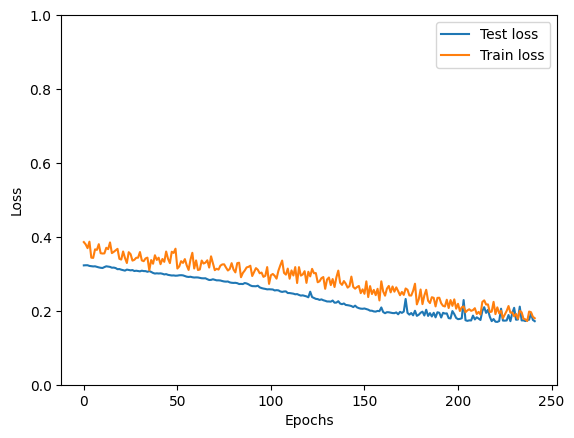

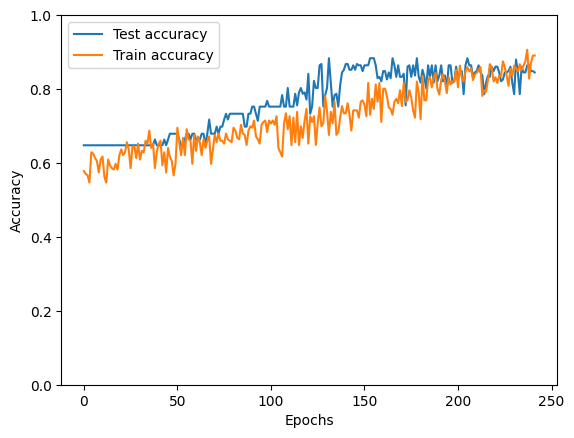

In [94]:
DEBUG = False
WEIGHTED = False
HYBRID = True

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

emb_dim = embeddings.shape[1]
audio_dim = audio_features.shape[1]
num_classes = len(df['dementia'].unique())

model = PittNet(emb_dim, audio_dim, num_classes, debug=DEBUG)
model = model.to(device)

'''
Passing as weighted is more correct, cuz we have high skew towards dementia data. However, this lowers
recall on dementia, i.e. we get more false negatives, but almost no false positives.
It's a trade off:
Weighted - more correct, but we misdiagnose some dementia as control
Not-weighted - a litle less correct, but we misdiagnose dementia less (however we risk misdiagnosing control)
'''
if WEIGHTED:
    class_imbalance = Counter(y_train)
    weights = 1.0 / torch.tensor([class_imbalance[0], class_imbalance[1]], dtype=torch.float32)  
    weights = weights / weights.sum()  # Normalized weights 
    print(f'Weights: {weights}')
    loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))
elif HYBRID:
    loss_fn = HybridLoss(alpha=0.5, gamma=1.5, ce_weight=0.4)
else:
    loss_fn = nn.CrossEntropyLoss()
    
print(f'Tokenizer model: {MODEL_TYPE} --- {"max pooling" if MAX_POOLING else "Average pooling"}')

optimizer = torch.optim.SGD([
                            {'params': model.audio_branch.parameters(), 'lr': 0.001},
                            {'params': model.embeddings_branch.parameters(), 'lr': 0.001},
                            {'params': model.demographics_branch.parameters(), 'lr': 0.001}
                            ], weight_decay=0.01)

debug_data = run_epochs(epochs=1000, patience=20, model=model, train_loader=train_loader, test_loader=test_loader, optimizer=optimizer, loss_fn=loss_fn, debug=DEBUG)




In [185]:
torch.save({
    'model_state': model.state_dict(),
    'text_dim': emb_dim,
    'audio_dim': audio_dim,
    'audio_scaler': train_dataset.audio_scaler,
    'age_scaler': train_dataset.age_scaler,
    'num_classes': num_classes,
    'class_names': ['Control', 'Dementia']
}, '/home/gabs/Documents/lab-NN/cognitive_impairments/data/models/TEST_MODEL.pth')

# Cross validation

In [ ]:
full_dataset = PittDataset(embeddings, audio_features, age, sex, labels)

n_splits = 10
sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.3)

fold_results = {
    'train_acc': [],
    'test_acc': [],
    'train_f1': [],
    'test_f1': [],
    'train_auc': [],
    'test_auc': [],
    'train_recall': [],
    'test_recall': [],
    'train_precision': [],
    'test_precision': [],
    'confusion_matrices': []
}

best_results = {
    'test_acc': 0.0,
    'test_f1': 0.0,
    'test_auc': 0.0,
    'test_recall': 0.0,
    'test_precision': 0.0,
}

for fold, (train_idx, test_idx) in enumerate(sss.split(embeddings, labels)):
    print(f"\n{'='*40}")
    print(f"Fold {fold + 1}/{n_splits}")
    print(f"{'='*40}")
    
    train_subset = Subset(full_dataset, train_idx)
    test_subset = Subset(full_dataset, test_idx)
    
    train_emb = embeddings[train_idx]
    train_audio = audio_features[train_idx]
    train_age = age[train_idx].reshape(-1, 1)
    train_sex = sex[train_idx].reshape(-1, 1)
    train_labels = labels[train_idx]
    
    test_emb = embeddings[test_idx]
    test_audio = audio_features[test_idx]
    test_age = age[test_idx].reshape(-1, 1)
    test_sex = sex[test_idx].reshape(-1, 1)
    test_labels = labels[test_idx]
    
    train_dataset = PittDataset(train_emb, train_audio, train_age, train_sex, train_labels)
    test_dataset = PittDataset(test_emb, test_audio, test_age, test_sex, test_labels, 
                             train_dataset.audio_scaler, train_dataset.age_scaler)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = PittNet(emb_dim, audio_dim, num_classes, debug=False)
    model = model.to(device)
    
    if WEIGHTED:
        class_imbalance = Counter(train_labels)
        weights = 1.0 / torch.tensor([class_imbalance[0], class_imbalance[1]], dtype=torch.float32)  
        weights = weights / weights.sum()  
        print(f'Weights: {weights}')
        loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))
    elif HYBRID:
        loss_fn = HybridLoss(alpha=0.5, gamma=1.5, ce_weight=0.4)
    else:
        loss_fn = nn.CrossEntropyLoss()
    print(f'Tokenizer model: {MODEL_TYPE} --- {"max pooling" if MAX_POOLING else "Average pooling"}')
    
    optimizer = torch.optim.SGD([
        {'params': model.audio_branch.parameters(), 'lr': 0.001},
        {'params': model.embeddings_branch.parameters(), 'lr': 0.001},
        {'params': model.demographics_branch.parameters(), 'lr': 0.001}
    ], weight_decay=0.01)
    
    final_metrics = run_epochs(epochs=1000, patience=30, model=model, train_loader=train_loader, 
                           test_loader=test_loader, optimizer=optimizer, 
                           loss_fn=loss_fn, debug=DEBUG, plots=False)
    
    fold_results['train_acc'].append(final_metrics['train_acc'])
    fold_results['test_acc'].append(final_metrics['test_acc'])
    fold_results['train_f1'].append(final_metrics['train_f1'])
    fold_results['test_f1'].append(final_metrics['test_f1'])
    fold_results['train_auc'].append(final_metrics['train_auc'])
    fold_results['test_auc'].append(final_metrics['test_auc'])
    fold_results['train_recall'].append(final_metrics['train_recall'])
    fold_results['test_recall'].append(final_metrics['test_recall'])
    fold_results['train_precision'].append(final_metrics['train_precision'])
    fold_results['test_precision'].append(final_metrics['test_precision'])
    fold_results['confusion_matrices'].append(final_metrics['test_confusion_matrix'])

    #if best_results['test_acc'] < final_metrics['test_acc'] and best_results['test_f1'] < final_metrics['test_f1'] and best_results['test_auc'] < final_metrics['test_auc'] and best_results['test_recall'] < final_metrics['test_recall'] and best_results['test_precision'] < final_metrics['test_precision']:
    if best_results['test_auc'] < final_metrics['test_auc'] and best_results['test_recall'] < final_metrics['test_recall']:
        best_results['test_acc'] = final_metrics['test_acc']
        best_results['test_f1'] = final_metrics['test_f1']
        best_results['test_auc'] = final_metrics['test_auc']
        best_results['test_recall'] = final_metrics['test_recall']
        best_results['test_precision'] = final_metrics['test_precision']
        torch.save({
            'model_state': model.state_dict(),
            'text_dim': emb_dim,
            'audio_dim': audio_dim,
            'audio_scaler': train_dataset.audio_scaler,
            'age_scaler': train_dataset.age_scaler,
            'num_classes': num_classes,
            'class_names': ['Control', 'Dementia']
        }, f"/home/gabs/Documents/lab-NN/cognitive_impairments/data/models/ACC{int(best_results['test_acc']*100)}_F1Sc{int(best_results['test_f1']*100)}_AUC{int(best_results['test_auc']*100)}_REC{int(best_results['test_recall']*100)}_PRE{int(best_results['test_precision']*100)}.pth")

print(f"\n\n{n_splits}-fold Cross-Validation Results Summary:")
print("="*50)
for metric in fold_results:
    if metric != 'confusion_matrices':
        values = fold_results[metric]
        print(f"{metric}: {np.mean(values):.2f} ± {np.std(values):.2f}")

avg_confusion = np.mean(fold_results['confusion_matrices'], axis=0)
print("\nAverage Confusion Matrix:")
print(f"Confusion matrix cheatsheet: \n{np.array([['TN', 'FP'], ['FN', 'TP']])}")
print(f"Average confusion matrix: \n{avg_confusion}")


Fold 1/10
Tokenizer model: bge-m3 --- Average pooling
Epoch 0:999------------------------
Train loss: 0.37100 | Train accuracy: 0.55 | Train F1: 0.65 | Train AUC: 0.52 | Train Recall: 0.63 | Train Precision: 0.67
Test loss: 0.32114 | Test accuracy: 0.64  | Test F1: 0.77 | Test AUC: 0.52 | Test Recall: 0.90 | Test Precision: 0.68
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[28 41]
 [49 85]]
Test confusion matrix: 
[[ 4 25]
 [ 6 52]]

Epoch 10:999------------------------
Train loss: 0.35477 | Train accuracy: 0.63 | Train F1: 0.74 | Train AUC: 0.55 | Train Recall: 0.80 | Train Precision: 0.69
Test loss: 0.31456 | Test accuracy: 0.67  | Test F1: 0.79 | Test AUC: 0.52 | Test Recall: 0.97 | Test Precision: 0.67
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[ 21  48]
 [ 27 107]]
Test confusion matrix: 
[[ 2 27]
 [ 2 56]]

Epoch 20:999------------------------
Train loss: 0.37288 | Train accuracy: 0.57 | Train F1: 0.69

/home/gabs/Documents/lab-NN/cognitive_impairments/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/gabs/Documents/lab-NN/cognitive_impairments/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/gabs/Documents/lab-NN/cognitive_impairments/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

Epoch 10:999------------------------
Train loss: 0.36089 | Train accuracy: 0.56 | Train F1: 0.67 | Train AUC: 0.47 | Train Recall: 0.70 | Train Precision: 0.64
Test loss: 0.32083 | Test accuracy: 0.67  | Test F1: 0.80 | Test AUC: 0.53 | Test Recall: 0.97 | Test Precision: 0.68
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[17 52]
 [40 94]]
Test confusion matrix: 
[[ 3 26]
 [ 2 56]]

Epoch 20:999------------------------
Train loss: 0.36182 | Train accuracy: 0.61 | Train F1: 0.72 | Train AUC: 0.52 | Train Recall: 0.78 | Train Precision: 0.67
Test loss: 0.31643 | Test accuracy: 0.68  | Test F1: 0.81 | Test AUC: 0.54 | Test Recall: 0.98 | Test Precision: 0.69
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[ 18  51]
 [ 29 105]]
Test confusion matrix: 
[[ 3 26]
 [ 1 57]]

Epoch 30:999------------------------
Train loss: 0.33632 | Train accuracy: 0.62 | Train F1: 0.73 | Train AUC: 0.53 | Train Recall: 0.79 | Train Precis

# SHAP


### Whole model

In [20]:
class WrappedPittNet(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model.eval()

    def forward(self, full_input):
        # full_input: [embeddings, audio, age, sex] concatenated
        emb_dim = self.model.embeddings_branch[0].in_features
        audio_dim = self.model.audio_branch[0].in_features

        embeddings = full_input[:, :emb_dim]
        audio = full_input[:, emb_dim:emb_dim+audio_dim]
        age = full_input[:, emb_dim+audio_dim].unsqueeze(1)
        sex = full_input[:, emb_dim+audio_dim+1].unsqueeze(1)

        logits, _ = self.model(embeddings, audio, age, sex)
        return logits


In [ ]:
# get a small background sample for SHAP 
X_background = torch.cat([
    train_dataset[:250]['embeddings'],
    train_dataset[:250]['audio_features'],
    train_dataset[:250]['age'],
    train_dataset[:250]['sex'],
], dim=1)

X_test = torch.cat([
    test_dataset[:50]['embeddings'],
    test_dataset[:50]['audio_features'],
    test_dataset[:50]['age'],
    test_dataset[:50]['sex'],
], dim=1)


In [23]:

wrapped_model = WrappedPittNet(model).to(device)
X_background = X_background.to(device)
X_test = X_test.to(device)

explainer = shap.GradientExplainer(wrapped_model, X_background)
shap_values = explainer.shap_values(X_test)

In [24]:
X_test.cpu().numpy().shape

(50, 858)

In [25]:
shap_values[:,:,0].shape

(50, 858)

In [26]:
audio_feat_names = df.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).columns

/tmp/ipykernel_121767/86062082.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:,:,1], X_test.cpu().numpy(), feature_names=feature_names, plot_size=[15, 6])


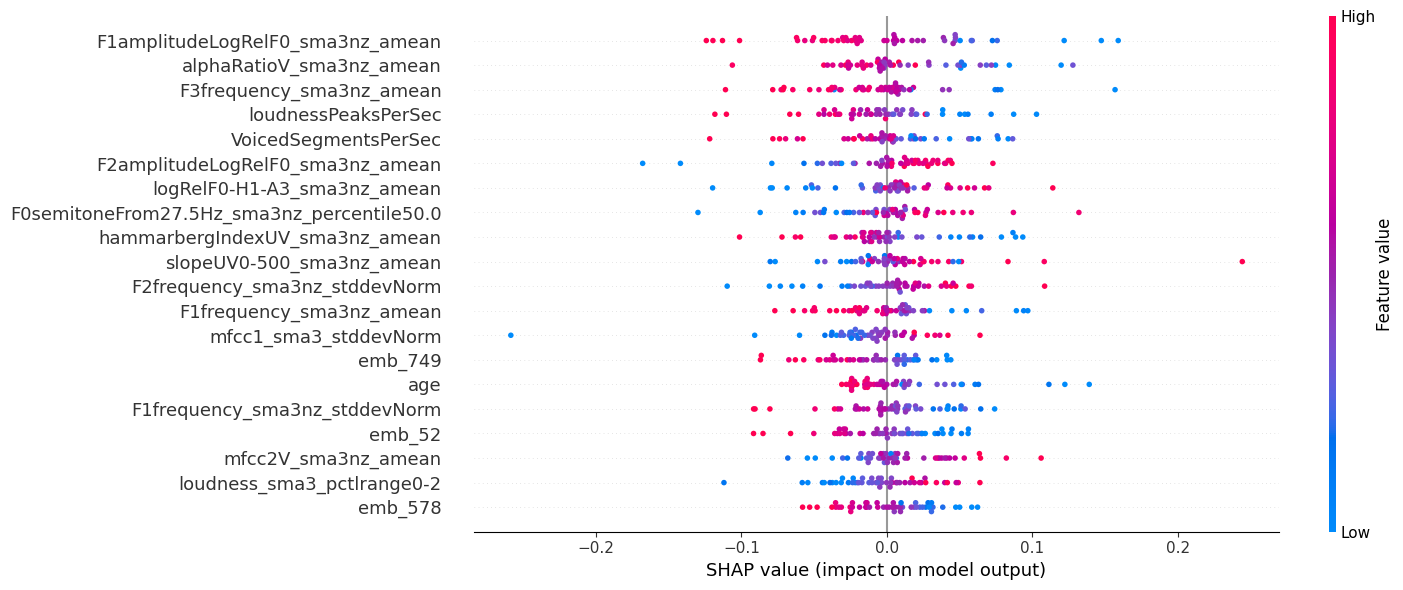

In [27]:
# 1 for dementia
emb_dim = embeddings.shape[1]
audio_dim = audio_features.shape[1]

feature_names = (
    [f"emb_{i}" for i in range(emb_dim)] +
    [f"{audio_feat_names[i]}" for i in range(audio_dim)] +
    ["age", "sex"]
)
shap.summary_plot(shap_values[:,:,1], X_test.cpu().numpy(), feature_names=feature_names, plot_size=[15, 6])


/tmp/ipykernel_121767/2210039106.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:,:,0], X_test.cpu().numpy(), feature_names=feature_names, plot_size=[15, 6])


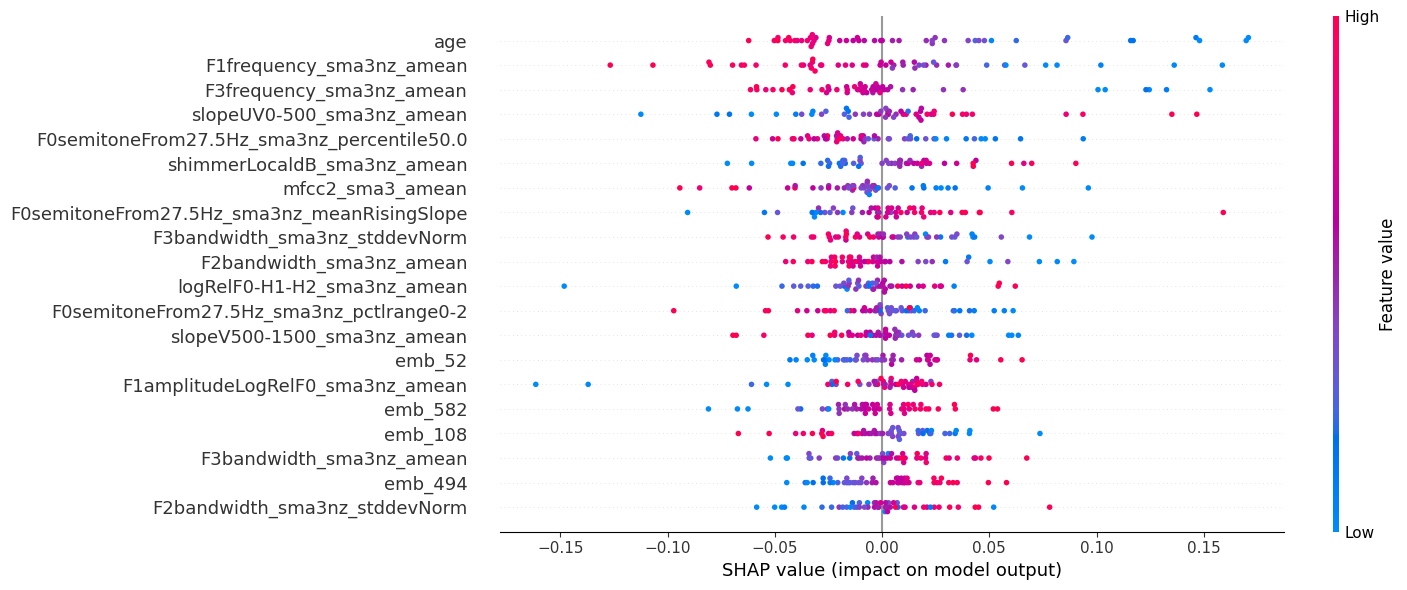

In [28]:
# 0 for control
shap.summary_plot(shap_values[:,:,0], X_test.cpu().numpy(), feature_names=feature_names, plot_size=[15, 6])

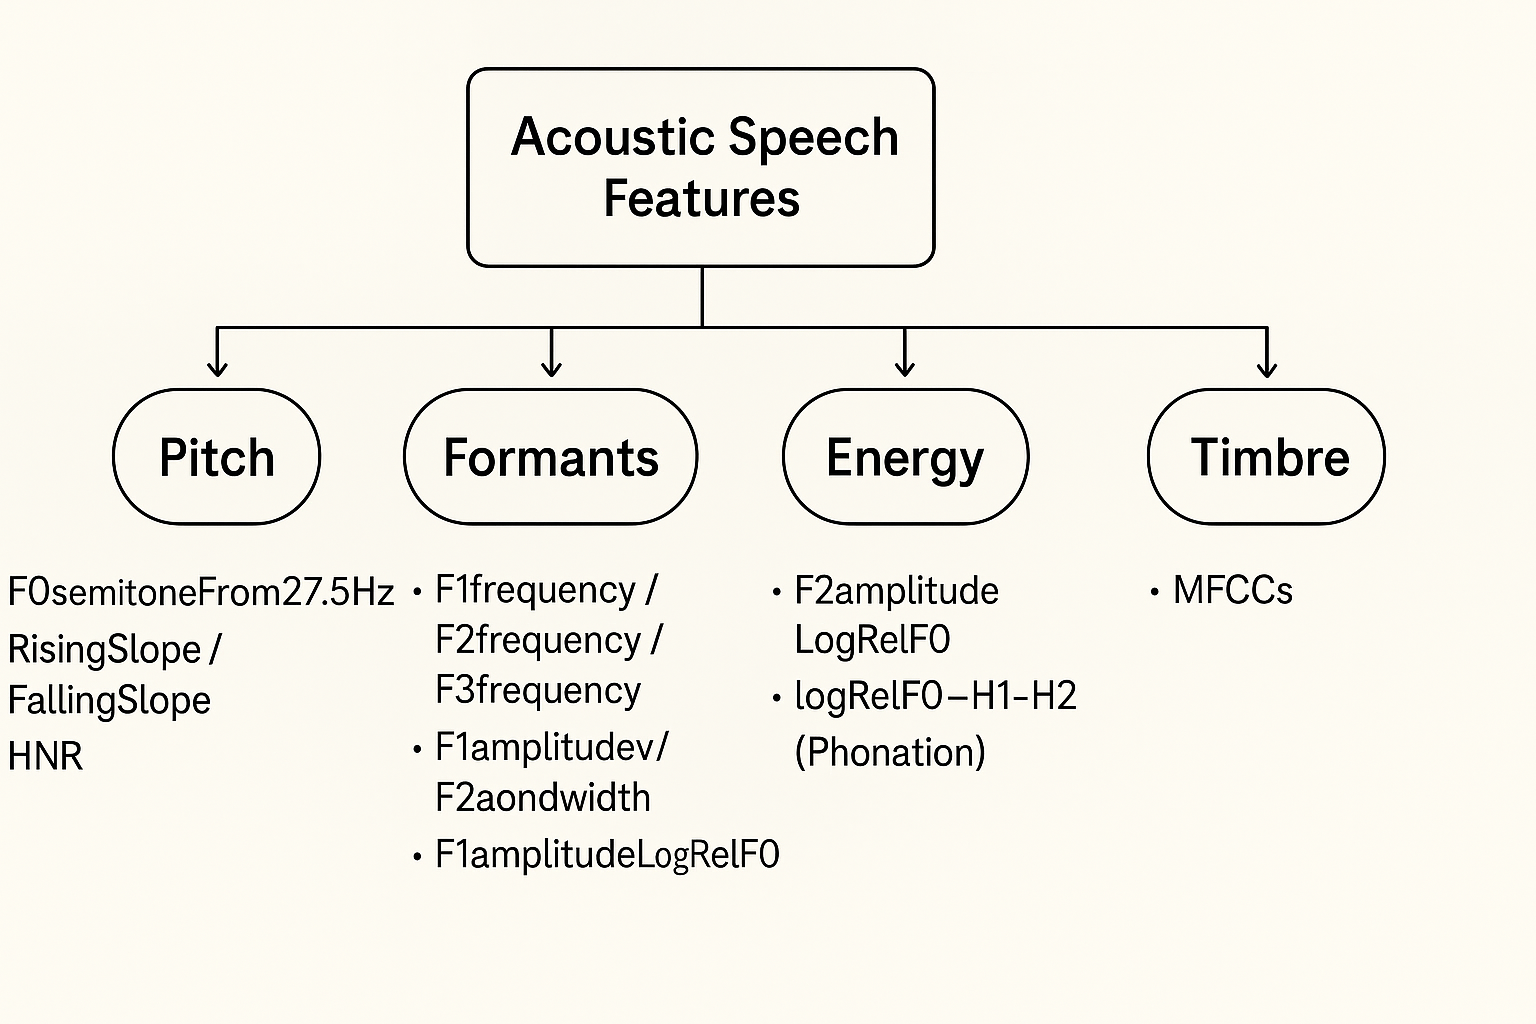

### Per branch

In [ ]:
shap_values_branch = shap_values[:, :, 1]  # Use dementia class SHAP values

emb_end = 768
audio_end = emb_end + 88
demo_end = audio_end + 2  # total: 860

shap_emb = shap_values_branch[:, :emb_end]
shap_audio = shap_values_branch[:, emb_end:audio_end]
shap_demo = shap_values_branch[:, audio_end:demo_end]

X_emb = X_test[:, :emb_end]
X_audio = X_test[:, emb_end:audio_end]
X_demo = X_test[:, audio_end:demo_end]


/tmp/ipykernel_66306/569300379.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_emb, X_emb.cpu().numpy(), feature_names=[f"emb_{i}" for i in range(emb_end)])


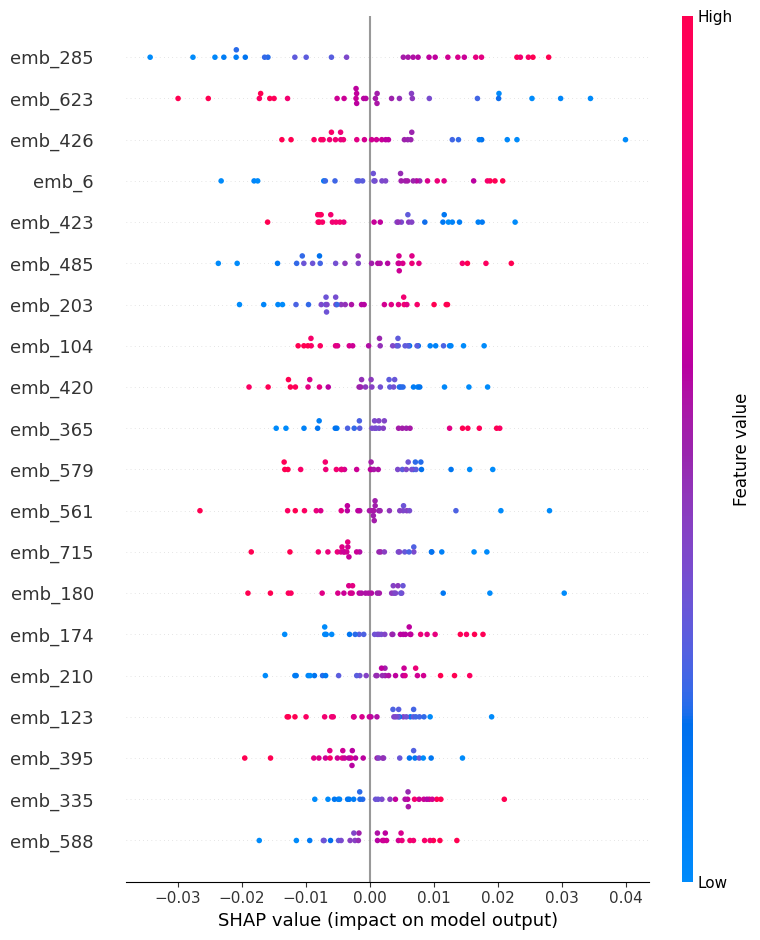

/tmp/ipykernel_66306/569300379.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_audio, X_audio.cpu().numpy(), feature_names=[f"{audio_feat_names[i]}" for i in range(audio_dim)])


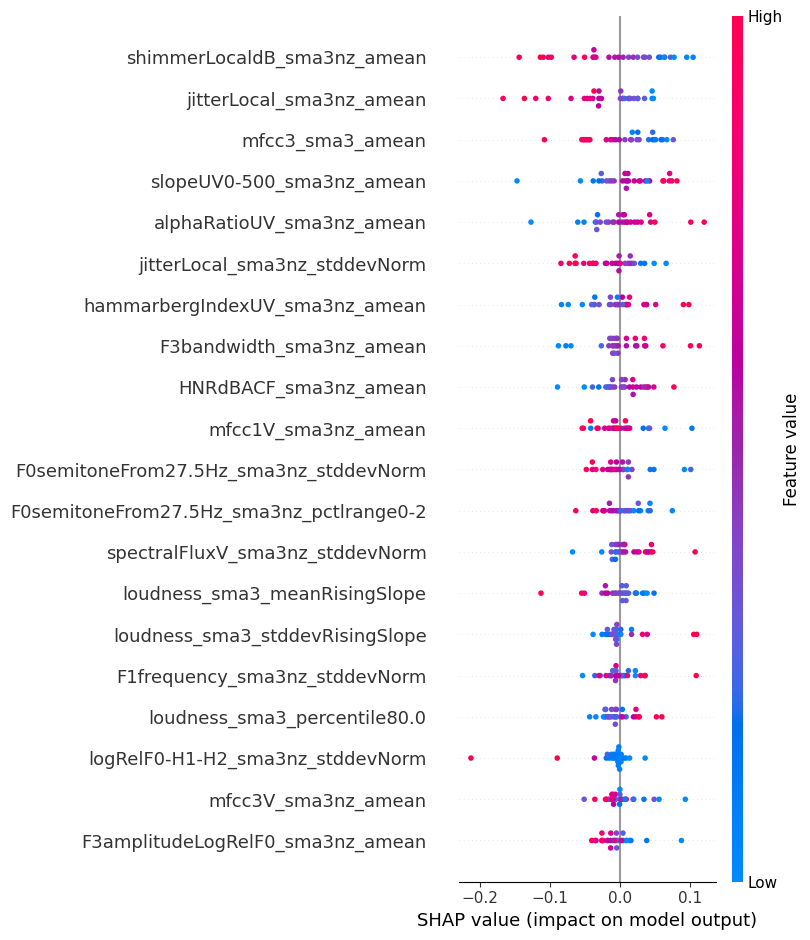

/tmp/ipykernel_66306/569300379.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_demo, X_demo.cpu().numpy(), feature_names=["age", "sex"])


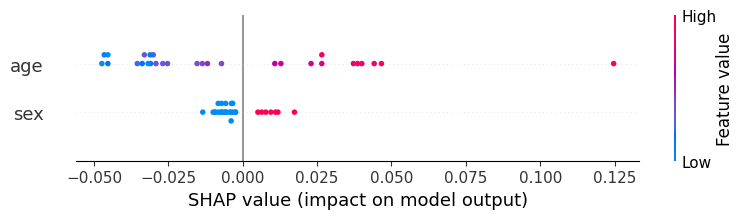

In [ ]:
shap.summary_plot(shap_emb, X_emb.cpu().numpy(), feature_names=[f"emb_{i}" for i in range(emb_end)])

shap.summary_plot(shap_audio, X_audio.cpu().numpy(), feature_names=[f"{audio_feat_names[i]}" for i in range(audio_dim)])

shap.summary_plot(shap_demo, X_demo.cpu().numpy(), feature_names=["age", "sex"])


# Predictor

In [30]:
PATH_TO_MODEL = '/home/gabs/Documents/lab-NN/cognitive_impairments/data/models/ACC92_F1Sc94_AUC91_REC96_PRE93.pth'
def predict(PATH_TO_MODEL, emb, audio_features, age, sex, best_threshold = None, numerical_sex=False):
    checkpoint = torch.load(f=PATH_TO_MODEL, weights_only=False)
    age_scaler = checkpoint['age_scaler']
    audio_scaler = checkpoint['audio_scaler']
    
    emb = torch.tensor(emb, dtype=torch.float32)
    audio_features = torch.tensor(audio_scaler.transform(audio_features), dtype=torch.float32)
    age = torch.tensor(age_scaler.transform([[age]]), dtype=torch.float32)
    if numerical_sex:
        sex = torch.tensor([[sex]], dtype=torch.float32)
    else:
        sex = torch.tensor([[0 if sex == 'F' else 1]], dtype=torch.float32)

    class_names = checkpoint['class_names']

    predictor = PittNet(checkpoint['text_dim'], checkpoint['audio_dim'], checkpoint['num_classes'])
    predictor.load_state_dict(checkpoint['model_state'])
    predictor.eval()

    with torch.inference_mode():
        logits, _ = predictor(emb, audio_features, age, sex)
        if best_threshold == None:
            pred = F.softmax(logits, dim=1)
            return {
            'probability': float(pred.max()),
            'class': class_names[pred.argmax(dim=1)],
            }
        else:
            prob = F.softmax(logits, dim=1)[:, 1]
            pred = (prob > best_threshold).int()
            return {
            'Dementia probability': float(prob),
            'class': class_names[pred],
            }
        
    
    
    

In [ ]:
adresso = pd.read_pickle('/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_ADRESSO.pkl')
SIMPLE=True
sex_mapping = {'female': 0,
               'male': 1}
dementia_mapping = {'Control' : 0,
                    'PossibleAD' : 1,
                    'ProbableAD' : 1,
                    'Probable' : 1,
                    'Memory' : 2,
                    'Vascular' : 3,
                    'MCI' : 4,
                    'Other' : 5}

simple_dementia_mapping = {'Control' : 0,
                    'PossibleAD' : 1,
                    'ProbableAD' : 1,
                    'Probable' : 1,
                    'Memory' : 1,
                    'Vascular' : 1,
                    'MCI' : 1,
                    'Other' : 1}
adresso['sex'] = adresso['sex'].map(sex_mapping)

# I suppose we can keep simple mapping, cuz 'PossibleAD' and 'ProbableAD' are the most common (like 80% of the data)
if SIMPLE:
    adresso['dementia'] = adresso['dementia'].map(simple_dementia_mapping)
else:
    adresso['dementia'] = adresso['dementia'].map(dementia_mapping)

adresso = adresso.dropna()

In [32]:
adresso

,ID,age,sex,dementia,embeddings,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
2,S136_cookie,79,1,1,"[[0.1622429, 0.06386103, 0.1419439, 0.01171796...",28.502918,0.092220,26.650621,28.916142,30.359406,...,0.004920,-0.006725,0.015559,1.277762,0.479977,0.498071,0.207255,3.254524,1.098766,-45.369053
3,S153_cookie,68,0,1,"[[-0.13641272, 0.025120603, 0.4695865, 0.02373...",33.893463,0.195800,30.401638,33.633354,36.526230,...,0.033429,-0.010736,0.087326,2.391511,1.363827,0.483929,0.312236,0.295405,0.324220,-25.333069
4,S143_cookie,60,0,1,"[[0.09699425, 0.13606128, 0.43917263, -0.20832...",30.126987,0.228446,25.005638,31.981270,33.638542,...,0.031159,-0.014041,0.038839,1.689608,1.531574,0.276114,0.340067,0.309781,0.287916,-26.715754
5,S118_cookie,77,0,1,"[[0.04755311, 0.2602899, 0.34900212, -0.059411...",30.478472,0.214575,26.783422,30.792650,33.569244,...,0.025279,-0.008670,0.079877,3.113026,2.623442,0.259634,0.180929,0.127193,0.134673,-28.666588
6,S110_cookie,73,0,1,"[[-0.20408152, 0.13424341, 0.1866002, 0.071866...",30.706264,0.130843,27.614120,31.195845,33.200001,...,0.025705,0.001578,0.022027,2.857491,1.092521,0.686296,0.158674,0.260018,0.183384,-32.373791
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,S055_cookie,70,1,0,"[[0.11069055, 0.025548514, 0.23647413, -0.0023...",24.407850,0.293110,19.424051,22.209169,28.354801,...,0.027329,-0.011826,0.491384,3.309641,2.750409,0.375573,0.256812,0.042723,0.019102,-20.087879
104,S015_cookie,70,0,0,"[[-0.07491915, -0.0036737747, 0.27406916, -0.0...",27.460943,0.247159,22.001646,26.952505,31.980383,...,0.009879,-0.004831,0.034917,4.049212,2.309686,0.190763,0.107259,0.207746,0.165789,-42.117378
105,S019_cookie,57,0,0,"[[-0.094108336, 0.24077725, 0.400946, 0.016361...",29.627216,0.259016,21.579857,31.489574,36.095100,...,0.041131,-0.009582,0.035128,2.410023,1.831259,0.380194,0.241024,0.229962,0.191916,-32.746468
106,S048_cookie,64,1,0,"[[-0.13421784, 0.27415794, 0.49581262, -0.0364...",21.962740,0.301942,17.423668,19.872877,25.061335,...,0.042658,-0.009217,0.100968,3.434928,1.872391,0.399952,0.219192,0.306400,0.374333,-28.437523


In [33]:
adresso_embeddings = np.stack(adresso['embeddings'].values)
adresso_audio_features = adresso.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).values
adresso_age = adresso['age'].values
adresso_sex = adresso['sex'].values
adresso_labels = adresso['dementia'].values

if len(adresso_embeddings.shape) > 2:
    adresso_embeddings = np.squeeze(adresso_embeddings, axis=1)

In [34]:
p_model = PittNet(emb_dim, audio_dim, num_classes)
p_model.load_state_dict(torch.load(f=PATH_TO_MODEL, weights_only=False)['model_state'])

<All keys matched successfully>

In [35]:
adresso_set = PittDataset(adresso_embeddings, adresso_audio_features, adresso_age, adresso_sex, adresso_labels)
adresso_loader = DataLoader(adresso_set, batch_size=32, shuffle=False)

In [ ]:
p_model.eval()
p_model = model.to(device)
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        emb = batch['embeddings'].to(device)
        audio = batch['audio_features'].to(device)
        age = batch['age'].to(device)
        sex = batch['sex'].to(device)
        labels = batch['label'].to(device)
        
        logits, _ = p_model(emb, audio, age, sex)
        
        probs = torch.softmax(logits, dim=1)[:, 1]  # probability of class 1 (dementia)
        
        all_preds.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

y_true = np.concatenate(all_labels)
y_scores = np.concatenate(all_preds)

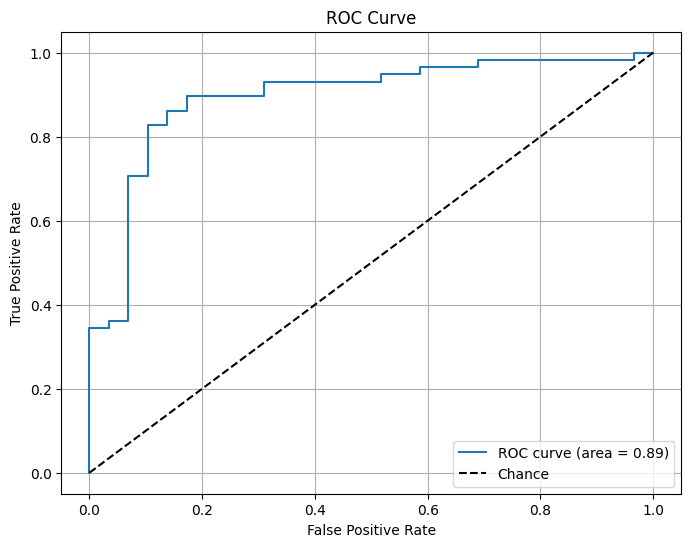

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = roc_auc_score(y_true, y_scores)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance') 
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid()
plt.show()


In [38]:
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_threshold = thresholds[best_idx]

print(f"Best Threshold by Youden's J: {best_threshold:.2f}")

Best Threshold by Youden's J: 0.76


In [40]:
#Resetting threshold for debugging
best_threshold = 0.5

In [ ]:
class_imbalance = Counter(adresso_labels)
weights = 1. / torch.tensor([class_imbalance[0], class_imbalance[1]], dtype=torch.float32)  
weights = weights / weights.sum()  
print(weights) 

loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))


with torch.inference_mode():
    p_model = p_model.to(device)

    p_model.eval()
    test_loss, test_acc = 0, 0

    all_test_preds = []
    all_test_labels = []
    
    for batch in adresso_loader:
        emb = batch['embeddings'].to(device)
        audio = batch['audio_features'].to(device)
        age = batch['age'].to(device)
        sex = batch['sex'].to(device)
        test_labels = batch['label'].to(device)
        test_logits, _ = p_model(emb, audio, age, sex)
        test_probs = F.softmax(test_logits, dim=1)[:, 1]
        loss = loss_fn(test_logits, test_labels)

        test_pred = (test_probs > best_threshold).int()

        test_loss += loss.item()
        test_acc += accuracy_score(test_labels.cpu(), test_pred.cpu())

        all_test_preds.extend(test_pred.cpu())
        all_test_labels.extend(test_labels.cpu())

    test_loss /= len(test_loader)
    test_acc /= len(test_loader)
    test_acc = accuracy_score(all_test_labels, all_test_preds)
    test_acc *= 100 # convert to %
    test_f1 = f1_score(all_test_labels, all_test_preds)
    test_auc = roc_auc_score(all_test_labels, all_test_preds)
    test_recall = recall_score(all_test_labels, all_test_preds)
    test_precision = precision_score(all_test_labels, all_test_preds)
    test_con_mat = confusion_matrix(all_test_labels, all_test_preds)
    test_report = classification_report(all_test_labels, all_test_preds)
    
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%  | Test F1: {test_f1:.2f} | Test AUC: {test_auc:.2f} | Test Recall: {test_recall:.2f} | Test Precision: {test_precision:.2f}")
    print(f"Confusion matrix cheatsheet: \n{np.array([['TP', 'FN'], ['FP', 'TN']])}")
    print(f"Test confusion matrix: \n{test_con_mat}\n")
    print(f'Test: \n{test_report}\n')
       
    print(all_test_preds)
    print(all_test_labels)

tensor([0.4906, 0.5094])
Test loss: 1.09646 | Test accuracy: 50.00%  | Test F1: 0.66 | Test AUC: 0.51 | Test Recall: 1.00 | Test Precision: 0.50
Confusion matrix cheatsheet: 
[['TP' 'FN']
 ['FP' 'TN']]
Test confusion matrix: 
[[ 1 53]
 [ 0 52]]

Test: 
              precision    recall  f1-score   support

           0       1.00      0.02      0.04        54
           1       0.50      1.00      0.66        52

    accuracy                           0.50       106
   macro avg       0.75      0.51      0.35       106
weighted avg       0.75      0.50      0.34       106


[tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32)

In [202]:
for i in range(105):
    adresso_embeddings = np.stack(adresso['embeddings'].values)[i]
    adresso_audio_features = adresso.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).values[i].reshape(1, -1)
    adresso_age = adresso['age'].values[i]
    adresso_sex = adresso['sex'].values[i]
    adresso_label = adresso['dementia'].values[i]

    if len(adresso_embeddings.shape) > 2:
        adresso_embeddings = np.squeeze(adresso_embeddings, axis=1)
    print('------------------')
    print(adresso_label)
    print(predict(PATH_TO_MODEL, adresso_embeddings, adresso_audio_features, adresso_age, adresso_sex, numerical_sex=True))

------------------
1
{'probability': 0.810393750667572, 'class': 'Dementia'}
------------------
1
{'probability': 0.8757587671279907, 'class': 'Dementia'}
------------------
1
{'probability': 0.8776484727859497, 'class': 'Dementia'}
------------------
1
{'probability': 0.9056530594825745, 'class': 'Dementia'}
------------------
1
{'probability': 0.8959349989891052, 'class': 'Dementia'}
------------------
1
{'probability': 0.8592215776443481, 'class': 'Dementia'}
------------------
1
{'probability': 0.5478663444519043, 'class': 'Control'}
------------------
1
{'probability': 0.7715389132499695, 'class': 'Dementia'}
------------------
1
{'probability': 0.5594080686569214, 'class': 'Control'}
------------------
1
{'probability': 0.9008183479309082, 'class': 'Dementia'}
------------------
1
{'probability': 0.8943338394165039, 'class': 'Dementia'}
------------------
1
{'probability': 0.8789064884185791, 'class': 'Dementia'}
------------------
1
{'probability': 0.8715561032295227, 'class': '

In [ ]:
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)

def aggregate_features(participant_dir):
    features = []
    for utterance_file in os.listdir(participant_dir):
        utterance_path = os.path.join(participant_dir, utterance_file)
        feat = smile.process_file(utterance_path) 
        features.append(feat.squeeze()) 
    
    return pd.DataFrame(features).mean(axis=0).to_dict()  


tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
bert_model = AutoModel.from_pretrained('bert-base-uncased')
def get_embeddings(text):
    inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=512)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state.mean(dim=1).numpy()  

In [46]:
with open('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/transcript/control_transcript_test.txt', "r") as fin:
    transcript = fin.readlines()[0]
test_embeddings = get_embeddings(transcript)
test_audio_feats = aggregate_features('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/audio/test_control/')
test_df = pd.DataFrame([test_audio_feats])
test_audio_feats = test_df.values
predict(PATH_TO_MODEL, test_embeddings, test_audio_feats, 88, 'M', best_threshold=best_threshold)

{'Dementia probability': 0.7171819806098938, 'class': 'Dementia'}

In [47]:
with open('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/transcript/demented_transcript_test.txt', "r") as fin:
    transcript = fin.readlines()[0]
test_embeddings = get_embeddings(transcript)
test_audio_feats = aggregate_features('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/audio/test_demented/')
test_df = pd.DataFrame([test_audio_feats])
test_audio_feats = test_df.values
predict(PATH_TO_MODEL, test_embeddings, test_audio_feats, 89, 'M', best_threshold=best_threshold)

{'Dementia probability': 0.8856819272041321, 'class': 'Dementia'}